Implement a Support Vector Machine (SVM) classifier from scratch without using scikit-learn, manually computing the optimal hyperplane using gradient descent and handling non-linearly separable data with soft margin techniques.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

df = df[features + [target]].dropna()

X = df[features].astype(float).to_numpy()
y = df[target].astype(int).to_numpy()

print("Dataset shape:", df.shape)
print("Features:", features)
print("Target classes:", np.unique(y))

Dataset shape: (79, 6)
Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Target classes: [0 1]


In [2]:
np.random.seed(42)

indices = np.random.permutation(len(X))
split = int(0.8 * len(X))

train_indices = indices[:split]
test_indices = indices[split:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

y_train = np.where(y_train == 1, 1, -1)
y_test = np.where(y_test == 1, 1, -1)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 63
Testing records: 16


In [3]:
def train_svm(X, y, learning_rate=0.001, C=1.0, epochs=2000):
    weights = np.zeros(X.shape[1])
    bias = 0
    losses = []

    n = len(y)

    for epoch in range(epochs):
        margins = y * (X @ weights + bias)
        active = margins < 1

        dw = weights - C * (X[active].T @ y[active]) / n
        db = -C * np.sum(y[active]) / n

        weights -= learning_rate * dw
        bias -= learning_rate * db

        margins = y * (X @ weights + bias)
        loss = (
            0.5 * np.sum(weights ** 2)
            + C * np.maximum(0, 1 - margins).mean()
        )
        losses.append(loss)

    return weights, bias, losses


weights, bias, losses = train_svm(
    X_train, y_train,
    learning_rate=0.001,
    C=1.0,
    epochs=2000
)

print("SVM training completed.")
print("Weights:", weights)
print("Bias:", round(bias, 4))

SVM training completed.
Weights: [ 0.15540619  0.10078638  0.03627157  0.03887014 -0.00978569]
Bias: 0.8748


In [4]:
scores = X_test @ weights + bias
predictions = np.where(scores >= 0, 1, -1)

tp = np.sum((y_test == 1) & (predictions == 1))
tn = np.sum((y_test == -1) & (predictions == -1))
fp = np.sum((y_test == -1) & (predictions == 1))
fn = np.sum((y_test == 1) & (predictions == -1))

accuracy = (tp + tn) / len(y_test) * 100
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("SVM Model Performance")
print("Accuracy:", round(accuracy, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1-Score:", round(f1 * 100, 2), "%")

SVM Model Performance
Accuracy: 81.25 %
Precision: 81.25 %
Recall: 100.0 %
F1-Score: 89.66 %


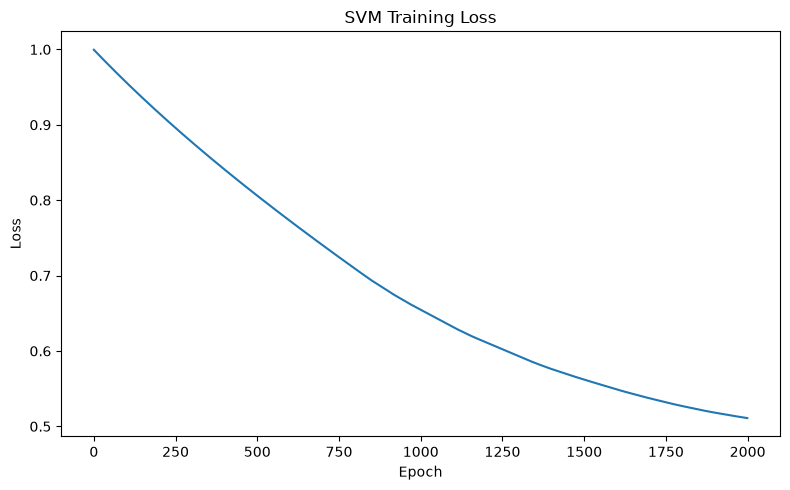

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SVM Training Loss")
plt.tight_layout()
plt.show()

In [7]:
print("Test accuracy:", round(accuracy, 2), "%")

Test accuracy: 81.25 %
